## **Tikhonov Regularisation**

In this notebook, we determine whether Tikhonov regularisation improves our parameter recovery.

In [1]:
# the whole API the experiment needs

import platform

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import scipy
import torch
from IPython.display import HTML
from scipy.optimize import minimize

import neuralphysics
from neuralphysics import (
    LIMB,
    SOURCE_SPECS,
    CoefficientHierarchy,
    ElectrodeArray,
    Observation,
    add_measurement_noise,
    configure,
    dipole_centres,
    forward,
    gaussian_dipole,
    grid_at,
    interfaces_from_logits,
    laplacian_metric_3D,
    levels,
    logits_from_interfaces,
    trapezoid_weight_field,
    viz,
)

In [2]:
print(configure())
print(f"neuralphysics {neuralphysics.__version__} | torch {torch.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | python {platform.python_version()}")
print(f"default dtype {torch.get_default_dtype()} | torch threads {torch.get_num_threads()} | "
      f"{platform.platform()}")

{'dtype': 'torch.float64', 'seed': 42}
neuralphysics 0.1.0 | torch 2.5.1 | numpy 1.26.4 | scipy 1.17.1 | python 3.11.15
default dtype torch.float64 | torch threads 4 | macOS-26.6.1-arm64-arm-64bit


In [3]:
# the forward experiment
# anything not named here is at the package default
# L = 1, z_zeta = 1, coarsening floor of 9, jacobi damping factor omega = 2/3, nu = (2, 2)
# 50 base iterations, and 100% electrode coverage on the four lateral faces

N = 65 # nodes per axis; N = 2^k + 1 must hold for the v-cycle to work
NUM_CYCLES = 8 # fixed budget - not a convergence tolerance
NOISE_PERCENT = 5.0 # surface electrode measurement noise, as a percentage of the clean field's RMS
NOISE_SEED = 0

In [4]:
# the inverse problem

# initialise our parameters away from the truth

# bone 8 mm and muscle 11.5 mm against the true values of 7 and 13, 
# which leaves fat at 3.5 mm against a true value of 3
# outermost radius is absent because we assume skin thickness to be known - so not recovered
# skin is a clinically invariant quantity in our experiment
RADII_INIT = (8.0 / 48.0, 19.5 / 48.0)

SIGMA_INIT = {"bone": 0.05, "muscle_T": 0.05, "muscle_L": 0.20, "fat": 0.02, "skin": 0.10}

MAX_ITERS = 1000 # L-BFGS-B iteration budget

# scipy's tolerances are calibrated for O(1) objectives. Here J ~ 1e-5 and
# ||grad J|| ~ 5e-6 near the solution, so the default gtol = 1e-5 is already satisfied
# at the starting point and L-BFGS-B would return after one evaluation having done
# nothing. ftol is relative to max(|f|, 1) = 1, so it is effectively absolute, and the
# default 2.2e-9 would stop while the misfit is still moving in the fourth digit.
FTOL = 1e-16
GTOL = 1e-12

SNAPSHOT_EVERY = 10     # how often to keep a predicted field for the panel figures
LIMB_RADIUS_MM = 24.0   # the physical limb radius, at r/R = 0.5

In [5]:
print(f"grid     N = {N}, levels {levels(N)}")
print(f"solver   {NUM_CYCLES} V-cycles")
print(f"data     {NOISE_PERCENT}% noise (seed {NOISE_SEED})")
print(f"inverse  L-BFGS-B, <= {MAX_ITERS} iterations, ftol {FTOL:g}, gtol {GTOL:g}")

grid     N = 65, levels [65, 33, 17, 9]
solver   8 V-cycles
data     5.0% noise (seed 0)
inverse  L-BFGS-B, <= 1000 iterations, ftol 1e-16, gtol 1e-12


In [6]:
# the tissue table - read off the model
print(f"{'layer':8s} {'r/R':>13s} {'thickness':>12s} {'sigma_T':>9s} {'sigma_L':>9s}   source")
r_lo = 0.0
for nm, r_hi in zip(LIMB.layer_names, LIMB.interfaces + (0.5,)):
    sT, sL = LIMB.sigma_layers[nm]
    print(f"{nm:8s} {f'{r_lo:.3f}-{r_hi:.3f}':>13s} "
          f"{(r_hi - r_lo) * LIMB_RADIUS_MM / 0.5:9.2f} mm {sT:9.2f} {sL:9.2f}   "
          f"{'PROVISIONAL' if nm in LIMB.provisional else 'Mesin (2013)'}")
    r_lo = r_hi

print(f"\nanisotropic layers: {sorted(LIMB.anisotropic_layers)}")
print(f"interface width  epsilon = {LIMB.epsilon:g} of L = {LIMB.epsilon * (N - 1):.2f} h at N = {N}")
print(f"geometry derived from Maksymenko et al. (2023); a {LIMB_RADIUS_MM:.0f} mm limb")

layer              r/R    thickness   sigma_T   sigma_L   source
bone       0.000-0.146      7.00 mm      0.02      0.02   PROVISIONAL
muscle     0.146-0.417     13.00 mm      0.09      0.40   Mesin (2013)
fat        0.417-0.479      3.00 mm      0.04      0.04   Mesin (2013)
skin       0.479-0.500      1.00 mm      0.05      0.05   PROVISIONAL

anisotropic layers: ['muscle']
interface width  epsilon = 0.00390625 of L = 0.25 h at N = 65
geometry derived from Maksymenko et al. (2023); a 24 mm limb


In [7]:
grid = grid_at(N)
det, rim = grid.det_J, grid.rim_stats(LIMB.shell_norm)

print(grid)
print(f"type(grid) = {type(grid)}")
print(f"rim radius  mean {rim['mean']:.5f}, spread {rim['spread']:.2e} "
      f"({rim['spread_in_h']:.3f} h)")
print(f"det(J)      min {float(det.min()):.5f}, max {float(det.max()):.5f}")
print(f"det(J)      has shape {det.shape}")
print("interfaces  " + ",  ".join(
    f"{a}/{b} {R:.2f} -> {grid.physical_shell_radius(R, LIMB.shell_norm):.4f}"
    for a, b, R in zip(LIMB.layer_names, LIMB.layer_names[1:], LIMB.interfaces)))

CylinderGrid(n=65, L=1.0, smoothing=SmoothingPolicy(iterations=100, del_t=0.2), z_zeta=1.0, mapped=True)
type(grid) = <class 'neuralphysics.grid.CylinderGrid'>
rim radius  mean 0.50144, spread 1.62e-02 (1.035 h)
det(J)      min 0.11417, max 1.11886
det(J)      has shape torch.Size([65, 65, 65])
interfaces  bone/muscle 0.15 -> 0.1463,  muscle/fat 0.42 -> 0.4179,  fat/skin 0.48 -> 0.4805


In [8]:
WIDTH = 0.05      # the 1/e blob radius, a physical length

sources, centres = [], []
for r_norm, angle in SOURCE_SPECS:
    centres.append(dipole_centres(grid, LIMB, r_blob_norm=r_norm, angle_deg=angle))
    sources.append(gaussian_dipole(grid, LIMB, width=WIDTH,
                                   r_blob_norm=r_norm, angle_deg=angle))

W = trapezoid_weight_field(grid.n)
for s, (I, c) in enumerate(zip(sources, centres)):
    clearance = min(c["r_blob"] - c["r_inner"], c["r_outer"] - c["r_blob"])
    print(f"source {s}: r = {c['r_blob']:.4f} at {c['angle_deg']:.0f} deg, "
          f"clearance {clearance:.4f} vs 2w = {2 * WIDTH:.2f}, "
          f"peak {float(I.abs().max()):.4f}, W.I = {float((W * I).sum()):.2e}")

print(f"muscle spans [{centres[0]['r_inner']:.4f}, {centres[0]['r_outer']:.4f}], "
      f"z: source {centres[0]['cz_source']:.3f}, sink {centres[0]['cz_sink']:.3f}, "
      f"w/h = {WIDTH / grid.h:.2f}")

source 0: r = 0.2507 at 0 deg, clearance 0.1045 vs 2w = 0.10, peak 0.9893, W.I = -4.47e-16
source 1: r = 0.3129 at 180 deg, clearance 0.1050 vs 2w = 0.10, peak 0.9871, W.I = -1.29e-17
muscle spans [0.1463, 0.4179], z: source 0.370, sink 0.630, w/h = 3.20


In [ ]:
coeff_true = CoefficientHierarchy.from_vectors(LIMB, N)

A = lambda f: laplacian_metric_3D(f, grid.h, coeff_true.faces[grid.n],
                                  coeff_true.metric[grid.n], coeff_true.sigma_T[grid.n])

phi_true = forward(sources[0], coeff_true, num_cycles=NUM_CYCLES)

In [11]:
array = ElectrodeArray()          # full coverage of the four lateral faces
mask_nodes = array.mask(grid.n)

observations = []
for s, I in enumerate(sources):
    phi_s = phi_true if s == 0 else forward(I, coeff_true, num_cycles=NUM_CYCLES)
    phi_obs, noise_stats = add_measurement_noise(phi_s, NOISE_PERCENT, NOISE_SEED + s)
    observations.append(Observation(phi=phi_obs, mask=mask_nodes, grid=grid))
    print(f"noise  source {s}: {NOISE_PERCENT:.1f}% of RMS {noise_stats['rms']:.3e} -> "
          f"std {noise_stats['noise_std']:.3e}, realised SNR {noise_stats['snr']:.2f}")

obs = observations[0]      # the field and residual figures are drawn for source 0
print(f"array  step {array.step}, coverage {array.coverage(grid.n):.3f}, "
      f"{int(obs.mask.sum())} electrodes of {grid.n ** 3} nodes")

noise  source 0: 5.0% of RMS 6.926e-04 -> std 3.463e-05, realised SNR 20.00
noise  source 1: 5.0% of RMS 7.093e-04 -> std 3.546e-05, realised SNR 20.02
array  step 1, coverage 1.000, 16640 electrodes of 274625 nodes


In [12]:
param_names = list(SIGMA_INIT)
sigma_true = torch.tensor([LIMB.sigma_layers["bone"][0],
                           LIMB.sigma_layers["muscle"][0],
                           LIMB.sigma_layers["muscle"][1],
                           LIMB.sigma_layers["fat"][0],
                           LIMB.sigma_layers["skin"][0]])
rho_ref = torch.log(torch.tensor([SIGMA_INIT[nm] for nm in param_names]))

n_sigma = len(param_names)
R_OUTER = LIMB.interfaces[-1]          # fat/skin surface: fixed, not recovered

u_true = logits_from_interfaces(LIMB.interfaces)
u_ref = logits_from_interfaces(RADII_INIT + (R_OUTER,))
theta_true = torch.cat([torch.log(sigma_true), u_true])
theta_ref = torch.cat([rho_ref, u_ref])


def unpack(theta):
    """(7,) parameters -> (sigma_T, sigma_L, interface radii).

    The first five are log-conductivities. bone, fat and skin appear in both vectors as
    the same tensor element, so an isotropic tissue's gradient accumulates into one
    scalar; muscle splits into T and L.

    The last two are softmax logits for the two inner interfaces. They are
    unconstrained: any real pair gives 0 < R_1 < R_2 < R_OUTER, so L-BFGS-B needs no
    bounds and no ordering constraint.
    """
    s = theta[:n_sigma].exp()
    return (torch.stack([s[0], s[1], s[3], s[4]]),      # bone, muscle_T, fat, skin
            torch.stack([s[0], s[2], s[3], s[4]]),      # bone, muscle_L, fat, skin
            interfaces_from_logits(theta[n_sigma:], R_OUTER))


def thicknesses_mm(interfaces):
    """Interface radii -> the four layer thicknesses in mm, skin closed off at the rim.

    A thickness is the anatomical quantity; a radius is a coordinate. Skin appears here
    even though it is not recovered, because it is the difference between R_OUTER and
    the rim and so is the one thickness fixed by assumption.
    """
    R = torch.as_tensor(interfaces).reshape(-1)
    edges = torch.cat([torch.zeros_like(R[:1]), R, torch.full_like(R[:1], 0.5)])
    return torch.diff(edges) * (LIMB_RADIUS_MM / 0.5)


sT_ref, sL_ref = LIMB.sigma_vectors()
sT_chk, sL_chk, R_chk = unpack(theta_true)
print(f"layers {LIMB.layer_names} | params {param_names} + logits u_1, u_2")
print(f"unpack(theta_true) reproduces the tissue table: "
      f"{torch.allclose(sT_chk, sT_ref) and torch.allclose(sL_chk, sL_ref)}")
print(f"          and round-trips the geometry: "
      f"{torch.allclose(R_chk, torch.as_tensor(LIMB.interfaces))}")
print(f"start sigma {[f'{v:.3f}' for v in rho_ref.exp().tolist()]}")
print(f"start  {[f'{v:.2f}' for v in thicknesses_mm(unpack(theta_ref)[2]).tolist()]} mm")
print(f"true   {[f'{v:.2f}' for v in thicknesses_mm(LIMB.interfaces).tolist()]} mm")

layers ('bone', 'muscle', 'fat', 'skin') | params ['bone', 'muscle_T', 'muscle_L', 'fat', 'skin'] + logits u_1, u_2
unpack(theta_true) reproduces the tissue table: True
          and round-trips the geometry: True
start sigma ['0.050', '0.050', '0.200', '0.020', '0.100']
start  ['8.00', '11.50', '3.50', '1.00'] mm
true   ['7.00', '13.00', '3.00', '1.00'] mm


In [13]:
mask = obs.mask
phi_obs_norm = float(torch.sqrt(sum((o.phi[mask] ** 2).sum() for o in observations)))

loss_history, sigma_history, interface_history = [], [], []
geometry_snapshots, phi_snapshots = [], []

print(f"{int(mask.sum())} electrode nodes | ||phi_obs|| on the mask = {phi_obs_norm:.4e}")
print(f"recovering {n_sigma} conductivities and 2 interface radii, "
      f"{n_sigma + 2} parameters in all")

16640 electrode nodes | ||phi_obs|| on the mask = 1.0105e-01
recovering 5 conductivities and 2 interface radii, 7 parameters in all


## Tikhonov regularisation

The objective above is a pure data misfit. Adding a penalty on the distance from a
reference conductivity, $J_\lambda(\theta) = J(\theta) + \tfrac{1}{2}\lambda\|\rho - \rho_{\rm ref}\|^2$,
trades fit against solution norm.

In [15]:
# Tikhonov sweep on the run above (5% noise). The observations are reused, so no data
# is regenerated; each lambda warm-starts from the previous solution, which is why this
# costs far less than seven cold runs.

LAMBDAS = [0.0, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]
thick_true = thicknesses_mm(LIMB.interfaces)


def run_lambda(lam, theta_start, max_iters=MAX_ITERS):
    def penalised(theta_np):
        theta = torch.tensor(theta_np, dtype=torch.float64, requires_grad=True)
        sT_vec, sL_vec, R = unpack(theta)
        c = CoefficientHierarchy.from_vectors(LIMB, N, sT_vec, sL_vec, interfaces=R)
        loss = sum(0.5 * ((forward(I, c, num_cycles=NUM_CYCLES) - o.phi)[mask] ** 2).sum()
                   for I, o in zip(sources, observations))
        loss = loss + 0.5 * lam * ((theta[:n_sigma] - rho_ref) ** 2).sum()
        loss.backward()
        return loss.item(), theta.grad.detach().numpy().copy()

    result = minimize(penalised, theta_start, jac=True, method="L-BFGS-B",
                   options={"maxiter": max_iters, "maxfun": 4 * max_iters,
                            "ftol": FTOL, "gtol": GTOL})

    theta_hat = torch.tensor(result.x)
    with torch.no_grad():
        sT_vec, sL_vec, R = unpack(theta_hat)
        c = CoefficientHierarchy.from_vectors(LIMB, N, sT_vec, sL_vec, interfaces=R)
        data = float(sum(0.5 * ((forward(I, c, num_cycles=NUM_CYCLES) - o.phi)[mask] ** 2).sum()
                         for I, o in zip(sources, observations)))
    sig = theta_hat[:n_sigma].exp()
    thick = thicknesses_mm(interfaces_from_logits(theta_hat[n_sigma:], R_OUTER))
    return {"lam": lam, "x": result.x.copy(), "data": data,
            "norm": float((theta_hat[:n_sigma] - rho_ref).norm()),
            "sigma_err": ((sig - sigma_true).abs() / sigma_true).tolist(),
            "thick_err": ((thick - thick_true).abs() / thick_true).tolist(),
            "nit": result.nit, "nfev": result.nfev}


sweep = []
start = theta_ref.numpy()
for lam in LAMBDAS:
    print(f"lambda = {lam:.0e} ...", flush=True)
    sweep.append(run_lambda(lam, start))
    start = sweep[-1]["x"]                      # warm start the next one
    r = sweep[-1]
    print(f"   {r['nit']:3d} iterations | data misfit {r['data']:.4e} | "
          f"||rho - rho_ref|| {r['norm']:.4f} | "
          + "  ".join(f"{n} {v:.1%}" for n, v in zip(param_names, r["sigma_err"])))

lambda = 0e+00 ...
   106 iterations | data misfit 2.0226e-05 | ||rho - rho_ref|| 1.6793 | bone 8.2%  muscle_T 0.2%  muscle_L 0.9%  fat 2.6%  skin 0.6%
lambda = 1e-09 ...
    33 iterations | data misfit 2.0226e-05 | ||rho - rho_ref|| 1.6731 | bone 7.7%  muscle_T 0.2%  muscle_L 0.8%  fat 2.1%  skin 0.2%
lambda = 1e-08 ...
    29 iterations | data misfit 2.0226e-05 | ||rho - rho_ref|| 1.6251 | bone 3.4%  muscle_T 0.2%  muscle_L 0.1%  fat 1.6%  skin 2.2%
lambda = 1e-07 ...
    71 iterations | data misfit 2.0242e-05 | ||rho - rho_ref|| 1.3950 | bone 20.9%  muscle_T 2.6%  muscle_L 4.8%  fat 21.9%  skin 16.1%
lambda = 1e-06 ...
    43 iterations | data misfit 2.0323e-05 | ||rho - rho_ref|| 1.2026 | bone 64.9%  muscle_T 3.4%  muscle_L 9.9%  fat 36.1%  skin 27.1%
lambda = 1e-05 ...
    91 iterations | data misfit 2.2503e-05 | ||rho - rho_ref|| 0.7536 | bone 149.9%  muscle_T 8.5%  muscle_L 19.9%  fat 43.1%  skin 50.5%
lambda = 1e-04 ...
    23 iterations | data misfit 2.9495e-05 | ||rho - rho_r

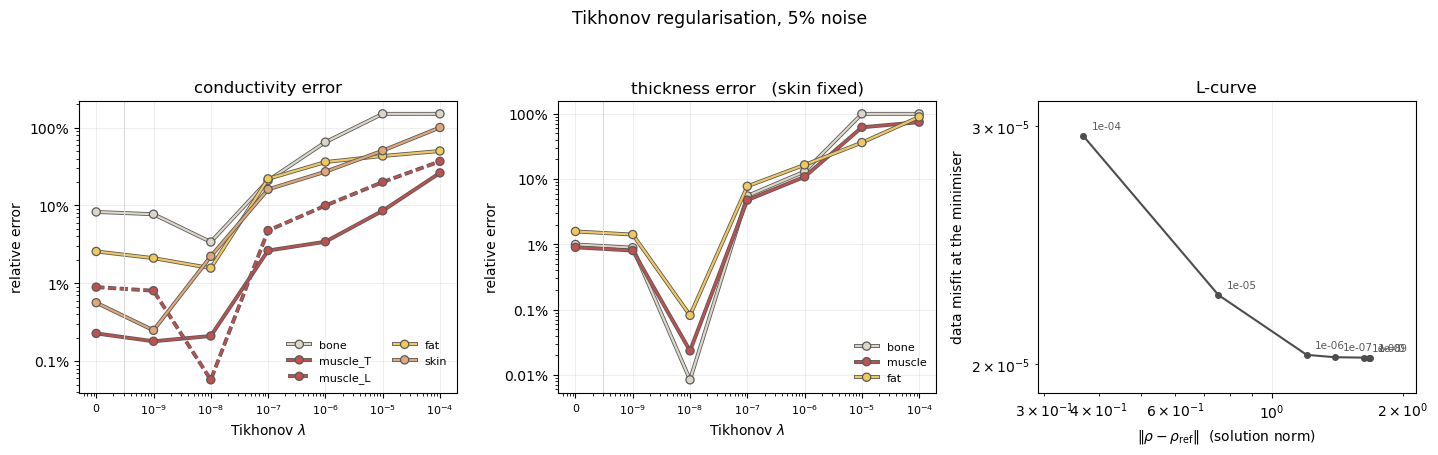

In [16]:
X0 = 1e-10        # where lambda = 0 is drawn on a log axis
halo = [pe.Stroke(linewidth=2.8, foreground="0.35"), pe.Normal()]
lam_x = [X0 if r["lam"] == 0 else r["lam"] for r in sweep]

fig_reg, ax_reg = plt.subplots(1, 3, figsize=(14.5, 4.6))

for i, nm in enumerate(param_names):
    colour, ls = viz.PARAM_STYLE[nm]
    ax_reg[0].plot(lam_x, [r["sigma_err"][i] for r in sweep], ls, color=colour,
                   marker="o", ms=4, lw=1.6, label=nm, path_effects=halo)
ax_reg[0].set_title("conductivity error")
ax_reg[0].legend(fontsize=8, frameon=False, ncol=2)

for i, nm in enumerate(LIMB.layer_names[:-1]):
    ax_reg[1].plot(lam_x, [r["thick_err"][i] for r in sweep], "-",
                   color=viz.TISSUE_COLOURS[nm], marker="o", ms=4, lw=1.6,
                   label=nm, path_effects=halo)
ax_reg[1].set_title("thickness error   (skin fixed)")
ax_reg[1].legend(fontsize=8, frameon=False)

for a in ax_reg[:2]:
    a.set_xscale("log"); a.set_yscale("log")
    a.set_xlabel(r"Tikhonov $\lambda$")
    a.set_ylabel("relative error")
    a.set_xticks(lam_x)
    a.set_xticklabels(["0"] + [f"$10^{{{int(np.log10(l))}}}$" for l in LAMBDAS[1:]], fontsize=8)
    a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:g}%"))
    a.axvline(X0 * 3, color="0.85", lw=0.8)
    a.grid(alpha=0.25, lw=0.6); a.set_axisbelow(True)

ax_reg[2].plot([r["norm"] for r in sweep], [r["data"] for r in sweep], "-o", color="0.3", ms=4)
for r in sweep:
    ax_reg[2].annotate(r"$\lambda=0$" if r["lam"] == 0 else f"{r['lam']:.0e}",
                       (r["norm"], r["data"]), textcoords="offset points",
                       xytext=(6, 5), fontsize=7.5, color="0.35")
ax_reg[2].set_xscale("log"); ax_reg[2].set_yscale("log")
ax_reg[2].set_xlabel(r"$\|\rho - \rho_{\rm ref}\|$  (solution norm)")
ax_reg[2].set_ylabel("data misfit at the minimiser")
ax_reg[2].set_title("L-curve")
ax_reg[2].margins(x=0.16, y=0.16)
ax_reg[2].grid(alpha=0.25, lw=0.6); ax_reg[2].set_axisbelow(True)

fig_reg.suptitle("Tikhonov regularisation, 5% noise", fontsize=12.5)
fig_reg.tight_layout(rect=(0, 0, 1, 0.93))